# PHÂN TÍCH ĐƠN BIẾN: AUTO BINNING + WoE / IV

In [20]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("/home/kieu/Documents/scorecard/DATA")
OUTPUT_DIR = Path("/home/kieu/Documents/scorecard/output")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. Nạp & khám phá nhanh dữ liệu

Hai cột đặc biệt cần "đánh dấu" ngay từ đầu:
- `TARGET`: nhãn nợ xấu (1 = bad)
- `SK_ID_CURR`: mã khách hàng — chỉ để định danh

In [21]:
TARGET = "TARGET"                       # cột nhãn: 1 = nợ xấu (bad), 0 = trả tốt (good)
EXCLUDE_COLS = ["SK_ID_CURR", TARGET]   # các cột KHÔNG đem đi binning

df = pd.read_csv(DATA_DIR / "data.csv")

print(f"Kích thước       : {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Bad rate tổng    : {df[TARGET].mean():.2%}")

missing_pct = df.isna().mean().sort_values(ascending=False)
print("\nTop 10 biến missing nhiều nhất:")
print((missing_pct.head(10) * 100).round(1).astype(str) + " %")

Kích thước       : 278,232 dòng x 127 cột
Bad rate tổng    : 8.35%

Top 10 biến missing nhiều nhất:
cc_total_atm_drawn       78.4 %
cc_avg_utilization       69.6 %
cc_util_12m              69.5 %
cc_total_drawings_cnt    69.3 %
cc_max_dpd               69.3 %
cc_dpd_3m                69.3 %
cc_dpd_cnt               69.3 %
cc_dpd_12m               69.3 %
cc_dpd_ratio             69.3 %
cc_dpd_9m                69.3 %
dtype: str


## 1b. Chia Train / Validation — trước khi binning

In [22]:
from sklearn.model_selection import train_test_split

VALID_SIZE = 0.25     
RANDOM_STATE = 42     

df_train, df_valid = train_test_split(
    df, test_size=VALID_SIZE, stratify=df[TARGET], random_state=RANDOM_STATE
)
df_train = df_train.reset_index(drop=True)
df_valid = df_valid.reset_index(drop=True)

print(f"Train      : {df_train.shape[0]:,} dòng | bad rate {df_train[TARGET].mean():.2%}")
print(f"Validation : {df_valid.shape[0]:,} dòng | bad rate {df_valid[TARGET].mean():.2%}")
print("-> Badrate tương đồng")

TRAIN_SPLIT_PATH = OUTPUT_DIR / "0.data_train_split.csv"
VALID_SPLIT_PATH = OUTPUT_DIR / "0.data_valid_split.csv"
df_train.to_csv(TRAIN_SPLIT_PATH, index=False)
df_valid.to_csv(VALID_SPLIT_PATH, index=False)
print(f"\n💾 Đã lưu: {TRAIN_SPLIT_PATH.name}, {VALID_SPLIT_PATH.name}")

# Từ đây trở đi, TOÀN BỘ binning của Buổi 2 chỉ chạy trên Train
df = df_train.copy()

Train      : 208,674 dòng | bad rate 8.35%
Validation : 69,558 dòng | bad rate 8.35%
-> Badrate tương đồng

💾 Đã lưu: 0.data_train_split.csv, 0.data_valid_split.csv


## 2. Lý thuyết: WoE và IV

**Weight of Evidence** của một bin:

$$WoE = \ln\left(\frac{dist\_good}{dist\_bad}\right) = \ln\left(\frac{\%\,khách\,tốt\,rơi\,vào\,bin}{\%\,khách\,xấu\,rơi\,vào\,bin}\right)$$

- $WoE > 0$: bin **tốt hơn** trung bình danh mục · $WoE < 0$: bin **xấu hơn** trung bình.

- Điểm WOE càng DƯƠNG (+),Khách hàng càng rủi ro thấp (Good cao) - Khách hàng càng rủi ro (Bad cao), điểm WOE càng ÂM (-).

**Information Value** của cả biến — cộng qua mọi bin:

$$IV = \sum_{bins} (dist\_good - dist\_bad) \times WoE$$

| IV | Đánh giá | Hành động |
|---|---|---|
| < 0.02 | Vô dụng | Loại |
| 0.02 – 0.1 | Yếu | Cân nhắc nếu ý nghĩa nghiệp vụ tốt |
| 0.1 – 0.3 | Trung bình | Ứng viên tốt |
| 0.3 – 0.5 | Mạnh | Ưu tiên giữ |
| **> 0.5** | **Nghi ngờ!** | **Kiểm tra data leakage trước khi mừng** |

**Tham số EPS** : nếu một bin thuần good (0 khách bad) thì $\ln(x/0)$ lỗi. Ta cộng một số cực nhỏ `EPS` vào cả tử và mẫu — nhỏ đến mức không ảnh hưởng kết quả, nhưng đủ để không bao giờ chia cho 0.

Kèm theo là hàm kiểm tra **trend đơn điệu**: bad rate phải tăng đều hoặc giảm đều qua các bin — trend răng cưa vừa khó giải trình với thẩm định, vừa dễ đảo chiều khi ra ngoài mẫu.

In [23]:
EPS = 1e-6   # chống log(0): cộng vào tử & mẫu khi tính WoE


def type_of_monotonic_trend(event_rates):
    """Phân loại HÌNH DẠNG bad rate qua các bin, dựa trên số lần đổi chiều:
         1  = tăng đều              (0 lần đổi chiều, luôn đi lên)
        -1  = giảm đều              (0 lần đổi chiều, luôn đi xuống)
         2  = hình chữ U            (đúng 1 lần đổi chiều: giảm rồi tăng — rủi ro cao 2 đầu)
        -2  = hình đồi (U ngược)    (đúng 1 lần đổi chiều: tăng rồi giảm — rủi ro cao ở giữa)
         0  = răng cưa thật         (từ 2 lần đổi chiều trở lên — không có hình dạng rõ ràng)
      -999  = không đủ bin để xét (0 hoặc 1 bin)

    QUAN TRỌNG: 2/-2 KHÔNG được gộp chung với 0. Hình U/hình đồi là TÍN HIỆU RỦI RO
    THẬT có câu chuyện nghiệp vụ (rủi ro cao ở 2 đầu hoặc ở giữa); răng cưa thật (0)
    thường chỉ là nhiễu mẫu. Xem Phần 3 (mục cảnh báo hình U) để biết cách xử lý.
    """
    if len(event_rates) <= 1:
        return -999
    d = np.diff(event_rates)          # hiệu số giữa các bin liền kề
    if np.all(d >= 0): return 1       # mọi bước đều đi lên
    if np.all(d <= 0): return -1      # mọi bước đều đi xuống

    # Đếm số lần đổi chiều thực sự (bỏ qua bước = 0 — không phải lên cũng không phải xuống)
    dau = np.sign(d[d != 0])
    if len(dau) == 0:
        return -999
    n_doi_chieu = int(np.sum(np.diff(dau) != 0))

    if n_doi_chieu == 1:
        return 2 if dau[0] < 0 else -2   # bắt đầu đi XUỐNG rồi lên -> U; bắt đầu đi LÊN rồi xuống -> đồi
    return 0   # >= 2 lần đổi chiều -> răng cưa thật


def calc_woe_iv(df_bins):
    """Nhận bảng bin (có cột good/bad/total), trả về bảng kèm WoE, IV, %."""
    df_bins = df_bins.copy()

    total_good = df_bins['good'].sum()
    total_bad = df_bins['bad'].sum()
    total_obs = df_bins['total'].sum()

    # Tỷ trọng phân bổ: bin này "chứa" bao nhiêu % tổng khách tốt / tổng khách xấu?
    df_bins['dist_good'] = df_bins['good'] / (total_good if total_good > 0 else 1)
    df_bins['dist_bad'] = df_bins['bad'] / (total_bad if total_bad > 0 else 1)

    # WoE (EPS chống log(0)) và đóng góp IV của từng bin
    df_bins['woe'] = np.log((df_bins['dist_good'] + EPS) / (df_bins['dist_bad'] + EPS))
    df_bins['iv'] = (df_bins['dist_good'] - df_bins['dist_bad']) * df_bins['woe']
    df_bins['%'] = df_bins['total'] / total_obs

    return df_bins

## 3. Gộp bin greedy — Greedy binning

Quy trình 2 pha của ngành:
- **Fine classing (chia mịn):** cắt biến thành nhiều bin nhỏ theo phân vị
- **Coarse classing (gộp thô):** gộp dần các bin kể cùng badrate về một số ít bin ổn định.

| Tham số | Giá trị | Vì sao |
|---|---|---|
| `MAX_PREBINS` | 40 | Chia mịn tối đa 40 bin — đủ chi tiết để thấy hình dạng, không quá vụn |
| `MIN_FINAL_BINS` | 3 | **Sàn**: dưới 3 bin thì biến hết khả năng phân biệt — WoE gần như nhị phân |
| `MAX_FINAL_BINS` | 5 | **Trần**: bảng điểm ≤ 5 dòng/biến — thẩm định đọc được, tránh overfit |
| `BASE_MIN_BIN_SIZE` | 0.05 | **Sàn dân số**: mỗi bin ≥ 5% — WoE tính trên đủ quan sát mới ổn định ngoài mẫu |
| `BASE_MAX_BIN_SIZE` | 0.70 | **Trần dân số**: không bin nào nuốt > 70% khách — một bin khổng lồ nghĩa là biến gần như không chia được |
| `MIN_EVENT_RATE_DIFF` | 0.005 | Hai bin cạnh nhau chênh bad rate < 0.5 điểm % thì coi như cùng rủi ro → buộc phải gộp |

**Vòng lặp gộp** dừng khi thỏa mãn cả 4 điều kiện, và không bao giờ tụt xuống dưới `MIN_FINAL_BINS`:

| Lý do phải gộp tiếp | Chọn cặp nào để gộp |
|---|---|
| Còn bin < `min_bin_size` | Gộp **bin mỏng nhất** với hàng xóm giống nó nhất về bad rate |
| Còn nhiều hơn `max_n_bins` bin | Gộp cặp liền kề **chênh bad rate nhỏ nhất** — miễn không tạo bin vượt trần 70% |
| Có cặp chênh bad rate < `min_event_rate_diff` | Gộp đúng cặp đó |

*Trực giác:* hai bin bad rate gần nhau đang "cùng 1 ngưỡng rủi ro" — gộp không mất thông tin, nhưng bin dày dân số hơn nên WoE **ổn định hơn khi ra ngoài mẫu**. Ngược lại, trần 70% chặn tình huống biến quá tập trung

In [24]:
MAX_PREBINS = 40           # số bin mịn tối đa (fine classing)
MIN_FINAL_BINS = 3         # SÀN số bin cuối — không gộp xuống dưới mức này
MAX_FINAL_BINS = 5         # TRẦN số bin cuối (optbinning mặc định 6)
BASE_MIN_BIN_SIZE = 0.05   # SÀN dân số: mỗi bin >= 5%
BASE_MAX_BIN_SIZE = 0.70   # TRẦN dân số: không bin nào > 70%
MIN_EVENT_RATE_DIFF = 0.005  # 2 bin cạnh nhau chênh bad rate < 0.5đ% -> buộc gộp

assert MIN_FINAL_BINS <= MAX_FINAL_BINS, "Sàn số bin không được lớn hơn trần!"


def gop_hai_bin(df, i, n_total):
    """Gộp bin thứ i và i+1 thành một: cộng dồn good/bad/total,
       nới biên phải của bin trái, tính lại badrate & % (mẫu số = n_total)."""
    df = df.copy()
    df.loc[i, 'good'] += df.loc[i + 1, 'good']
    df.loc[i, 'bad'] += df.loc[i + 1, 'bad']
    df.loc[i, 'total'] += df.loc[i + 1, 'total']
    df.loc[i, 'max'] = df.loc[i + 1, 'max']      # nuốt luôn biên phải của bin bên phải

    df.loc[i, 'badrate'] = df.loc[i, 'bad'] / df.loc[i, 'total']
    df.loc[i, '%'] = df.loc[i, 'total'] / n_total

    return df.drop(i + 1).reset_index(drop=True)   # xóa bin đã bị nuốt


def merge_adjacent_bins(df_bins, n_total, min_pct, max_pct,
                        min_bins=MIN_FINAL_BINS, max_bins=MAX_FINAL_BINS,
                        min_rate_diff=MIN_EVENT_RATE_DIFF):
    """Coarse classing bằng Greedy Merging với 5 ràng buộc:
         - số bin trong khoảng [min_bins, max_bins]
         - mỗi bin thuộc [min_pct, max_pct] dân số
         - 2 bin cạnh nhau phải chênh bad rate >= min_rate_diff
       n_total = TOÀN BỘ dân số của biến (kể cả Missing/Special) -> mọi % cùng mẫu số."""
    df_bins = df_bins.copy().reset_index(drop=True)

    # Vòng lặp dừng ngay khi chạm SÀN số bin, dù các ràng buộc khác chưa thỏa
    while len(df_bins) > min_bins:
        pcts = df_bins['%'].values
        diffs = np.abs(np.diff(df_bins['badrate'].values))   # chênh bad rate từng cặp liền kề
        if len(diffs) == 0:
            break

        # --- Ba lý do buộc phải gộp tiếp ---
        qua_nhieu_bin = len(df_bins) > max_bins                  # vượt trần số bin
        co_bin_mong = pcts.min() < min_pct                       # có bin dưới sàn dân số
        co_cap_qua_giong = bool((diffs < min_rate_diff).any())   # 2 bin kể cùng câu chuyện

        if not (qua_nhieu_bin or co_bin_mong or co_cap_qua_giong):
            break   # đã thỏa mọi ràng buộc -> dừng

        # --- Chọn cặp để gộp ---
        if co_bin_mong:
            # Ưu tiên tuyệt đối: cứu bin mỏng nhất, ghép với hàng xóm giống nó nhất.
            # (Trường hợp này được phép vượt trần max_pct — thà bin to còn hơn bin rỗng.)
            j = int(np.argmin(pcts))
            if j == 0:
                idx = 0                                  # bin đầu -> chỉ có hàng xóm bên phải
            elif j == len(df_bins) - 1:
                idx = j - 1                              # bin cuối -> chỉ có hàng xóm bên trái
            else:
                idx = j - 1 if diffs[j - 1] <= diffs[j] else j   # chọn bên giống hơn
        else:
            # Gộp cặp giống nhau nhất, NHƯNG bỏ qua cặp sẽ tạo bin vượt TRẦN 70%
            thu_tu = np.argsort(diffs)   # từ giống nhất -> khác nhất
            idx = next((int(i) for i in thu_tu if pcts[i] + pcts[i + 1] <= max_pct), None)
            if idx is None:
                break   # mọi cặp đều đụng trần -> dừng, giữ nguyên bảng bin

        df_bins = gop_hai_bin(df_bins, idx, n_total)

    return df_bins

### Ép trend đơn điệu — tương đương `monotonic_trend` của optbinning (TÙY CHỌN)

Bản gốc `optbinning` fit **hai lần** cho mỗi biến số: một lần ép `monotonic_trend='ascending'`, một lần `'descending'`, rồi ghi cả hai phương án vào báo cáo để người phân tích chọn. Ta làm tương tự nhưng đúng nghĩa hơn: **mỗi biến luôn được bin theo cả hai cách**, không có cờ bật/tắt nào quyết định "cách nào là thật":

1. **Bảng GỐC** — kết quả trực tiếp của greedy merge (Phần 3), giữ nguyên hình dạng tự nhiên dù đơn điệu hay không.
2. **Bảng ĐÃ ÉP** — bảng GỐC đi qua thêm một vòng gộp nữa: **nếu trend còn không đơn điệu thì gộp tiếp** cặp vi phạm nặng nhất cho đến khi đơn điệu (hoặc chạm sàn `MIN_FINAL_BINS`).

Vì đây là **hai bảng bin có khoảng cắt (`cut_point`) khác nhau thật sự** — không phải hai cách gắn nhãn lên cùng một bảng — nên khi xuất báo cáo hàng loạt ở Phần 6, chúng phải nằm ở **hai sheet riêng**, không được gộp chung một bảng.

Chiều đơn điệu (ép theo hướng tăng hay giảm) được suy ra từ dữ liệu, không áp đặt trước.

In [25]:
def enforce_monotonic_trend(df_bins, n_total, min_bins=MIN_FINAL_BINS):
    """Gộp tiếp các cặp vi phạm cho đến khi bad rate đơn điệu qua các bin.
       Luôn được gọi cho MỌI biến số trong bin_variable — không có cờ bật/tắt."""
    df_bins = df_bins.copy().reset_index(drop=True)

    while len(df_bins) > min_bins:
        rates = df_bins['badrate'].values
        if type_of_monotonic_trend(rates) in (1, -1):
            break   # đã đơn điệu -> xong

        d = np.diff(rates)
        chieu = 1 if d.sum() >= 0 else -1        # chiều "đa số" của dữ liệu
        vi_pham = np.where(d * chieu < 0)[0]     # các bước đi ngược chiều
        if len(vi_pham) == 0:
            break

        # Gộp cặp vi phạm NẶNG NHẤT (bước ngược chiều lớn nhất)
        idx = int(vi_pham[np.argmax(np.abs(d[vi_pham]))])
        df_bins = gop_hai_bin(df_bins, idx, n_total)

    return df_bins

### Trường hợp riêng: biến hình chữ U / hình đồi 

- **Bảng GỐC** (mang cột `trend_raw`) — khoảng cắt (`cut_point`) đúng như greedy merge sinh ra, chưa đụng tới.
- **Bảng ĐÃ ÉP** (mang cột `current_trend`) — khoảng cắt đã bị **gộp lại** cho tới khi đơn điệu. Số bin ở bảng này **luôn ≤** bảng gốc, vì cách duy nhất để một chuỗi bad rate hết răng cưa/hết hình U là gộp bớt các bin đang đi ngược chiều.

Cả hai bảng đều mang **đủ cả hai cột** `trend_raw` và `current_trend` để tiện đối chiếu, dù khoảng cắt thực tế của mỗi bảng khác nhau. Khi xuất Excel ở Phần 6, hai bảng này nằm ở **hai sheet riêng**: `bin_theo_trend_raw` và `bin_theo_trend_ep`.

Hai cột trend **chỉ bằng nhau khi biến vốn đã đơn điệu sẵn** (`trend_raw ∈ {1,-1}` thì ép cũng chẳng gộp gì thêm, hai bảng trùng nhau).

| Mã | Hình dạng | Ý nghĩa nghiệp vụ |
|---|---|---|
| `1` / `-1` | Đơn điệu | Rủi ro tăng/giảm đều — lý tưởng, không cần xử lý gì thêm |
| `2` | **Hình chữ U** (giảm rồi tăng) | Rủi ro cao ở **hai đầu**, thấp ở giữa |
| `-2` | **Hình đồi** (tăng rồi giảm) | Rủi ro cao ở **giữa**, thấp ở hai đầu |
| `0` | Răng cưa thật (≥ 2 lần đổi chiều) | Nhiễu mẫu, không có câu chuyện rõ ràng — ứng viên để loại |



In [26]:
def so_sanh_iv_ep_don_dieu(df, col, target_col):
    """So sánh IV giữa bảng GỐC (trend_raw) và bảng ĐÃ ÉP (current_trend) cho MỘT biến.
       Không cần toggle cờ gì — bin_variable luôn trả về sẵn cả hai bảng."""
    goc, da_ep = bin_variable(df, col, target_col)

    if goc is None or da_ep is None:
        print(f"{col}: không bin được (biến hằng số hoặc lỗi).")
        return goc, da_ep

    iv_goc, iv_ep = goc['iv_total'].iloc[0], da_ep['iv_total'].iloc[0]
    n_goc = goc['cut_point'].astype(str).str.startswith('[').sum()
    n_ep = da_ep['cut_point'].astype(str).str.startswith('[').sum()
    mat_iv_pct = (1 - iv_ep / iv_goc) * 100 if iv_goc > 0 else 0

    print(f"{col}")
    print(f"  Bảng GỐC   (trend_raw={goc['trend_raw'].iloc[0]})     : IV = {iv_goc:.4f}  | {n_goc} bin")
    print(f"  Bảng ĐÃ ÉP (current_trend={da_ep['current_trend'].iloc[0]})  : IV = {iv_ep:.4f}  | {n_ep} bin")
    print(f"  -> Ép đơn điệu làm MẤT {mat_iv_pct:.1f}% IV của biến này"
          f"{'  ⚠️ MẤT NHIỀU — cân nhắc phương án 1 hoặc 2 ở trên' if mat_iv_pct > 30 else ''}")
    return goc, da_ep


### Nhóm đặc biệt: Missing & Special values

Hai nhóm **không tham gia** gộp bin — mỗi nhóm là một dòng riêng với WoE riêng trong bảng luật:
- **Missing**: khách thin-file thiếu dữ liệu — thường có bad rate khác biệt rõ, tức missing *là* tín hiệu. Không bao giờ "điền trung bình" rồi coi như xong;
- **Special values**: các mã quy ước kỹ thuật (ở đây `±999999999999` — kiểu giá trị hệ thống nguồn dùng đánh dấu "không áp dụng"). Để lẫn vào phân phối thật, chúng phá nát các điểm cắt phân vị.

In [27]:
SPECIAL_VALUES = [999999999999, -999999999999]   # mã quy ước cần tách riêng


def add_extra_group(df_subset, label):
    """Tạo dòng tổng hợp (good/bad/total) cho nhóm Missing hoặc Special."""
    if len(df_subset) > 0:
        bad = df_subset['target'].sum()
        total = len(df_subset)
        return pd.DataFrame([{
            'cut_point': label, 'min': np.nan, 'max': np.nan,
            'good': total - bad, 'bad': bad, 'total': total
        }])
    return pd.DataFrame()

## 4. Lắp ráp: hàm bin MỘT biến hoàn chỉnh

Gộp toàn bộ những gì vừa học thành một "nhà máy" xử lý một biến. Đọc theo flow:

1. **Tách 3 nhóm:** Missing / Special / Valid;
2. **Nhánh categorical** (kiểu chữ, hoặc ≤ 2 giá trị): group theo giá trị; giá trị hiếm (< 5% dân số) gộp vào `OTHERS`;
3. **Nhánh numerical:** `pd.qcut` chia mịn theo phân vị → gộp greedy (5 ràng buộc, ngưỡng cố định) → *(tùy chọn)* ép đơn điệu → **mở rộng 2 đầu mút ra ±vô cực**;
4. Nối lại Missing/Special → `calc_woe_iv` → gắn trend, IV tổng.

In [28]:
def bin_variable(df, col, target_col):
    """Bin MỘT biến, trả về TUPLE (bins_raw, bins_enforced):
         - bins_raw       : bảng bin GỐC — khoảng cắt trực tiếp từ greedy merge, chưa ép
         - bins_enforced   : bảng bin ĐÃ ÉP — bins_raw đi qua thêm một vòng gộp để đơn điệu
       Cả hai bảng đều mang đủ cột current_trend & trend_raw để đối chiếu.
       Trả về (None, None) nếu biến hằng số hoặc không bin được.
    """
    tmp = df[[col, target_col]].copy()
    tmp.columns = ['value', 'target']

    if tmp['value'].nunique(dropna=True) <= 1:
        return None, None   # biến hằng số — không có gì để học

    # Nhận diện biến định tính BỀN với mọi phiên bản pandas.
    # (dtype == 'object' hỏng trên pandas 2.x: cột chữ đọc từ CSV có thể mang dtype
    #  'string'/'str', khiến biến chữ bị đẩy nhầm sang nhánh số và vỡ ở qcut)
    is_categorical = not pd.api.types.is_numeric_dtype(tmp['value'])

    # --- BƯỚC 1: tách 3 nhóm ---
    df_missing = tmp[tmp['value'].isna()]
    df_special = tmp[tmp['value'].isin(SPECIAL_VALUES)] if not is_categorical else pd.DataFrame()
    df_valid = tmp[tmp['value'].notna() & ~tmp['value'].isin(SPECIAL_VALUES)]

    n_total = len(tmp)

    # --- BƯỚC 2A: nhánh CATEGORICAL ---
    if is_categorical or tmp['value'].nunique(dropna=True) <= 2:
        grouped = df_valid.groupby('value')['target'].agg(total='count', bad='sum').reset_index()
        grouped['%'] = grouped['total'] / n_total

        # Giá trị hiếm (< 5% dân số) gộp vào OTHERS
        small_cats = grouped[grouped['%'] < BASE_MIN_BIN_SIZE]['value']
        df_valid['value'] = df_valid['value'].apply(lambda x: 'OTHERS' if x in small_cats.values else x)

        final_bins = df_valid.groupby('value')['target'].agg(total='count', bad='sum').reset_index()
        final_bins['good'] = final_bins['total'] - final_bins['bad']
        final_bins.rename(columns={'value': 'cut_point'}, inplace=True)
        final_bins['min'] = np.nan
        final_bins['max'] = np.nan

        trend_raw = 0   # biến định tính không có thứ tự -> khái niệm hình dạng vô nghĩa
        trend_val = 0
        bins_raw = final_bins
        bins_enforced = final_bins.copy()   # không có khái niệm "ép" cho biến định tính -> 2 bảng giống nhau

    # --- BƯỚC 2B: nhánh NUMERICAL ---
    else:
        if len(df_valid) > 0:
            # (i) Fine classing: chia mịn theo phân vị (qcut); fallback cut nếu nhiều giá trị trùng
            try:
                df_valid['bin_interval'] = pd.qcut(df_valid['value'], q=MAX_PREBINS, duplicates='drop')
            except Exception:
                df_valid['bin_interval'] = pd.cut(df_valid['value'], bins=MAX_PREBINS)

            grouped = df_valid.groupby('bin_interval')['target'].agg(total='count', bad='sum').reset_index()
            grouped['good'] = grouped['total'] - grouped['bad']
            grouped['badrate'] = grouped['bad'] / grouped['total']
            grouped['%'] = grouped['total'] / n_total     # mẫu số = TOÀN BỘ dân số của biến
            grouped['min'] = grouped['bin_interval'].apply(lambda x: x.left).astype(float)
            grouped['max'] = grouped['bin_interval'].apply(lambda x: x.right).astype(float)

            # Biến toàn số nguyên -> làm tròn biên bin cho đẹp bảng luật
            if np.nanmax(df_valid['value'].values % 1) == 0:
                grouped['min'] = np.ceil(grouped['min'])
                grouped['max'] = np.ceil(grouped['max'])

            grouped = grouped.sort_values('min').reset_index(drop=True)

            # (ii) Coarse classing: gộp greedy với đủ 5 ràng buộc, ngưỡng CỐ ĐỊNH cho mọi biến
            #      -> đây CHÍNH LÀ bảng GỐC (bins_raw)
            bins_raw = merge_adjacent_bins(
                grouped, n_total,
                min_pct=BASE_MIN_BIN_SIZE, max_pct=BASE_MAX_BIN_SIZE,
                min_bins=MIN_FINAL_BINS, max_bins=MAX_FINAL_BINS,
                min_rate_diff=MIN_EVENT_RATE_DIFF,
            )
            trend_raw = type_of_monotonic_trend(bins_raw['badrate'].values)

            # (iii) Gộp TIẾP từ bins_raw cho tới khi đơn điệu -> bảng ĐÃ ÉP (bins_enforced)
            #      LUÔN chạy — không có cờ bật/tắt. Đây là bảng bin THỨ HAI, độc lập, khoảng
            #      cắt khác bins_raw thật sự (không phải chỉ đổi nhãn).
            bins_enforced = enforce_monotonic_trend(bins_raw.copy(), n_total, MIN_FINAL_BINS)
            trend_val = type_of_monotonic_trend(bins_enforced['badrate'].values)

            # (iv) Mở rộng 2 đầu mút ra vô cực — đón khách hàng tương lai ngoài vùng min-max.
            #      Áp dụng RIÊNG cho từng bảng vì số bin/biên của 2 bảng khác nhau.
            for b in (bins_raw, bins_enforced):
                if len(b) > 0:
                    b.loc[b.index[0], 'min'] = float('-inf')
                    b.loc[b.index[-1], 'max'] = float('inf')
                    b['cut_point'] = b.apply(lambda row: f"[{row['min']}, {row['max']})", axis=1)
        else:
            bins_raw = pd.DataFrame()
            bins_enforced = pd.DataFrame()
            trend_raw = 0
            trend_val = 0

    # --- BƯỚC 3-4: đóng gói MỘT bảng (nối Missing/Special, tính WoE/IV, sắp cột) ---
    def _dong_goi(bins_df):
        out = pd.concat([
            bins_df,
            add_extra_group(df_special, f"Outlier({SPECIAL_VALUES})"),
            add_extra_group(df_missing, 'Missing')
        ], ignore_index=True)

        if out.empty:
            return None

        out = calc_woe_iv(out)
        out['variable'] = col
        out['iv_total'] = out['iv'].sum()
        out['current_trend'] = trend_val   # hình dạng của BẢNG ĐÃ ÉP — giống nhau ở cả 2 bảng output
        out['trend_raw'] = trend_raw       # hình dạng của BẢNG GỐC — giống nhau ở cả 2 bảng output
        out['bin_no'] = range(1, len(out) + 1)
        out['description'] = np.nan
        out['badrate'] = out['bad'] / out['total']

        # IV chỉ tính trên phần non-missing — so sánh "sức mạnh thuần" giữa các biến
        out['iv_nonmissing'] = out[out['cut_point'] != 'Missing']['iv'].sum()

        cols_order = ['variable', 'bin_no', 'cut_point', 'min', 'max', 'good', 'bad', 'total',
                      'badrate', '%', 'woe', 'iv', 'iv_total', 'iv_nonmissing',
                      'current_trend', 'trend_raw', 'description']
        return out[cols_order]

    return _dong_goi(bins_raw), _dong_goi(bins_enforced)


## 5. Test 1 biến trước khi chạy hàng loạt

In [29]:
demo_raw, demo_enforced = bin_variable(df, 'AMT_CREDIT', TARGET)
demo_raw[['bin_no', 'cut_point', 'total', '%', 'badrate', 'woe', 'iv', 'iv_total',
          'current_trend', 'trend_raw']].round(4)

,bin_no,cut_point,total,%,badrate,woe,iv,iv_total,current_trend,trend_raw
0,1,"[-inf, 170640.0)",15975,0.0766,0.0615,0.3295,0.0073,0.0581,-1,-2
1,2,"[170640.0, 298512.0)",36713,0.1759,0.0845,-0.0141,0.0000,0.0581,-1,-2
2,3,"[298512.0, 660469.5)",72525,0.3476,0.1049,-0.2526,0.0246,0.0581,-1,-2
3,4,"[660469.5, 1113840.0)",57444,0.2753,0.0752,0.1129,0.0033,0.0581,-1,-2
4,5,"[1113840.0, inf)",26017,0.1247,0.0538,0.4715,0.0228,0.0581,-1,-2


In [30]:
thuong = demo_raw[~demo_raw['cut_point'].isin(['Missing']) &
                   ~demo_raw['cut_point'].astype(str).str.contains('Outlier')]
rates = thuong['badrate'].values

print(f"Số bin thường      : {len(thuong)}  (sàn {MIN_FINAL_BINS} - trần {MAX_FINAL_BINS})")
print(f"Bin nhỏ nhất       : {thuong['%'].min():.2%}  (sàn {BASE_MIN_BIN_SIZE:.0%})")
print(f"Bin lớn nhất       : {thuong['%'].max():.2%}  (trần {BASE_MAX_BIN_SIZE:.0%})")
print(f"Chênh bad rate min : {np.abs(np.diff(rates)).min():.4f}  (tối thiểu {MIN_EVENT_RATE_DIFF})")
print(f"Trend GỐC (trend_raw)      : {thuong['trend_raw'].iloc[0]:>3}  "
      f"(1=tăng, -1=giảm, 2=chữ U, -2=hình đồi, 0=răng cưa)")
print(f"Trend NẾU ÉP (current_trend) : {thuong['current_trend'].iloc[0]:>3}  "
      f"{'<- khác trend gốc: bảng ĐÃ ÉP có khoảng cắt khác bảng GỐC' if thuong['trend_raw'].iloc[0] != thuong['current_trend'].iloc[0] else '<- giống trend gốc: biến vốn đã đơn điệu sẵn, 2 bảng trùng nhau'}")

Số bin thường      : 5  (sàn 3 - trần 5)
Bin nhỏ nhất       : 7.66%  (sàn 5%)
Bin lớn nhất       : 34.76%  (trần 70%)
Chênh bad rate min : 0.0204  (tối thiểu 0.005)
Trend GỐC (trend_raw)      :  -2  (1=tăng, -1=giảm, 2=chữ U, -2=hình đồi, 0=răng cưa)
Trend NẾU ÉP (current_trend) :  -1  <- khác trend gốc: bảng ĐÃ ÉP có khoảng cắt khác bảng GỐC


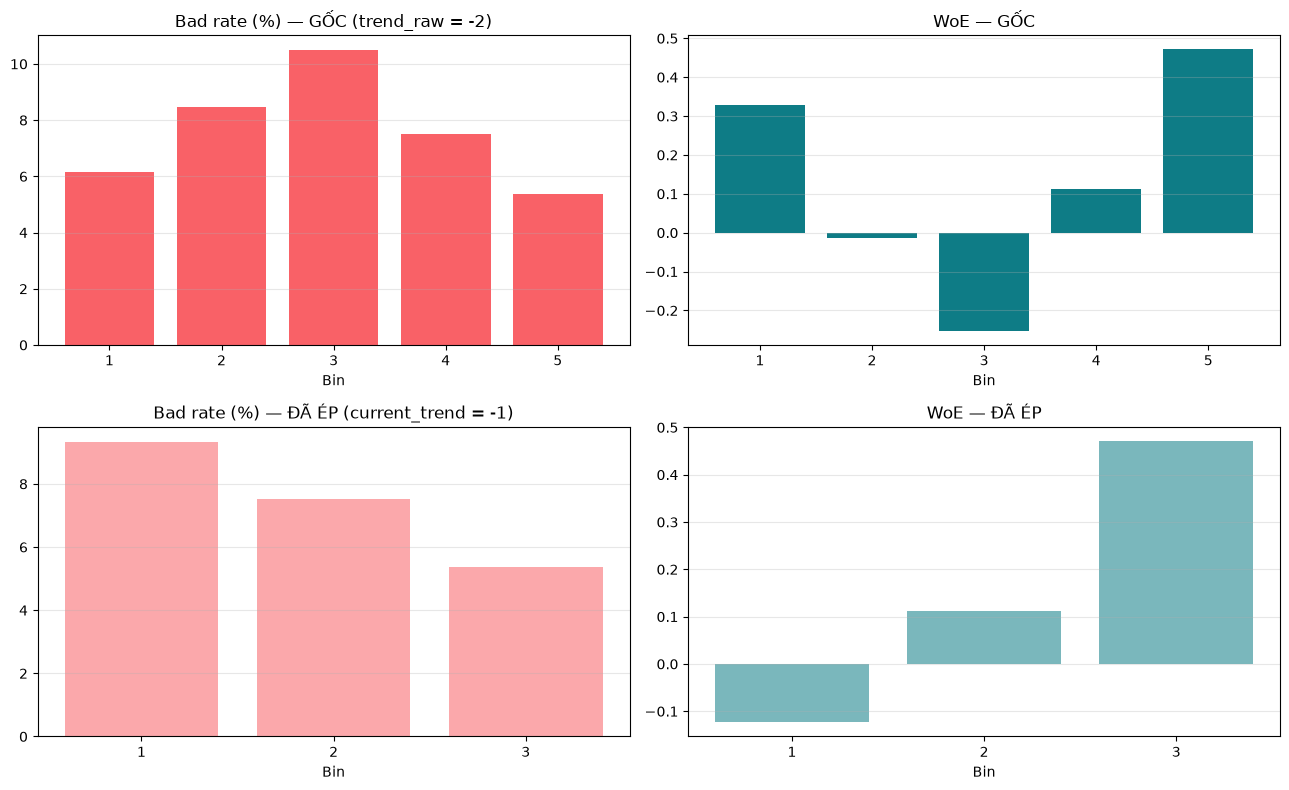

Số bin : GỐC = 5  ->  ĐÃ ÉP = 3
IV     : GỐC = 0.0581  ->  ĐÃ ÉP = 0.0358  (mất 38.4% IV nếu dùng bảng đã ép)


In [31]:
# Trực quan hóa: bad rate và WoE theo bin — hàng trên = bảng GỐC, hàng dưới = bảng ĐÃ ÉP
def _bins_thuong(bins_df):
    return bins_df[~bins_df['cut_point'].isin(['Missing']) &
                    ~bins_df['cut_point'].astype(str).str.contains('Outlier')]

plot_df = _bins_thuong(demo_raw)
plot_df_ep = _bins_thuong(demo_enforced) if demo_enforced is not None else plot_df.iloc[0:0]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].bar(plot_df['bin_no'].astype(str), plot_df['badrate'] * 100, color='#F96167')
axes[0, 0].set_title(f"Bad rate (%) — GỐC (trend_raw = {plot_df['trend_raw'].iloc[0]})")
axes[0, 1].bar(plot_df['bin_no'].astype(str), plot_df['woe'], color='#0E7C86')
axes[0, 1].set_title('WoE — GỐC')

if len(plot_df_ep) > 0:
    axes[1, 0].bar(plot_df_ep['bin_no'].astype(str), plot_df_ep['badrate'] * 100, color='#F96167', alpha=0.55)
    axes[1, 0].set_title(f"Bad rate (%) — ĐÃ ÉP (current_trend = {plot_df_ep['current_trend'].iloc[0]})")
    axes[1, 1].bar(plot_df_ep['bin_no'].astype(str), plot_df_ep['woe'], color='#0E7C86', alpha=0.55)
    axes[1, 1].set_title('WoE — ĐÃ ÉP')
else:
    for ax in axes[1]:
        ax.text(0.5, 0.5, "Không có bin (biến hằng số/lỗi)", ha='center', va='center')

for ax in axes.flat:
    ax.set_xlabel('Bin')
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

if demo_enforced is not None:
    mat_iv = (1 - demo_enforced['iv_total'].iloc[0] / demo_raw['iv_total'].iloc[0]) * 100 \
        if demo_raw['iv_total'].iloc[0] > 0 else 0
    print(f"Số bin : GỐC = {len(plot_df)}  ->  ĐÃ ÉP = {len(plot_df_ep)}")
    print(f"IV     : GỐC = {demo_raw['iv_total'].iloc[0]:.4f}  ->  ĐÃ ÉP = {demo_enforced['iv_total'].iloc[0]:.4f}"
          f"  (mất {mat_iv:.1f}% IV nếu dùng bảng đã ép)")


## 6. Chạy binning toàn bộ biến & xuất báo cáo

Vòng lặp qua mọi biến (trừ `SK_ID_CURR` và `TARGET`). Biến lỗi được skip có thông báo — không làm sập cả quá trình. Kết quả gộp thành **một bảng luật duy nhất** 

In [32]:
BINNING_REPORT_PATH = OUTPUT_DIR / "1.binning_survey_report.xlsx"

tables_raw, tables_enforced = [], []
var_list = [col for col in df.columns if col not in EXCLUDE_COLS]

print(f"Bắt đầu Binning cho {len(var_list)} biến...")
for col in tqdm(var_list):
    try:
        res_raw, res_enforced = bin_variable(df, col, TARGET)
        if res_raw is not None:
            tables_raw.append(res_raw)
        if res_enforced is not None:
            tables_enforced.append(res_enforced)
    except Exception as e:
        print(f"Skip {col} do lỗi: {e}")

binning_report_raw = pd.concat(tables_raw, ignore_index=True)
binning_report_enforced = pd.concat(tables_enforced, ignore_index=True)

# --- Xuất 2 SHEET RIÊNG: bin GỐC và bin ĐÃ ÉP là 2 bảng có khoảng cắt khác nhau thật sự,
#     gộp chung 1 sheet sẽ lẫn lộn cut_point/woe/iv giữa 2 phiên bản của cùng 1 biến. ---
with pd.ExcelWriter(BINNING_REPORT_PATH) as writer:
    binning_report_raw.to_excel(writer, sheet_name="bin_theo_trend_raw", index=False)
    binning_report_enforced.to_excel(writer, sheet_name="bin_theo_trend_ep", index=False)

print(f"\n✅ Đã xuất báo cáo: {BINNING_REPORT_PATH}")
print(f"   Sheet 'bin_theo_trend_raw' : {binning_report_raw['variable'].nunique()} biến · "
      f"{len(binning_report_raw)} dòng bin  (khoảng cắt GỐC, chưa ép)")
print(f"   Sheet 'bin_theo_trend_ep'  : {binning_report_enforced['variable'].nunique()} biến · "
      f"{len(binning_report_enforced)} dòng bin  (khoảng cắt ĐÃ ép đơn điệu)")

# --- Cảnh báo riêng: biến HÌNH CHỮ U / HÌNH ĐỒI — KHÔNG phải răng cưa ngẫu nhiên ---
# (trend_raw/current_trend giống nhau ở cả 2 sheet cho cùng 1 biến, nên lấy từ sheet nào cũng được)
hinh_dang = (binning_report_raw.groupby('variable')
             .agg(trend_raw=('trend_raw', 'first'),
                  trend_neu_ep=('current_trend', 'first'),
                  iv_total=('iv_total', 'first'))
             .reset_index())

ushape = hinh_dang[hinh_dang['trend_raw'].isin([2, -2])].sort_values('iv_total', ascending=False)

if len(ushape) > 0:
    print(f"\n⚠️  {len(ushape)} biến có HÌNH CHỮ U / HÌNH ĐỒI (rủi ro không đơn điệu nhưng CÓ câu chuyện,"
          f" khác với răng cưa nhiễu):")
    for _, r in ushape.iterrows():
        hinh = "chữ U (rủi ro cao 2 đầu)" if r['trend_raw'] == 2 else "hình đồi (rủi ro cao ở giữa)"
        print(f"   - {r['variable']:<32} IV={r['iv_total']:.4f}  hình {hinh}  "
              f"-> so sánh 2 sheet trong Excel, hoặc chạy "
              f"so_sanh_iv_ep_don_dieu(df, '{r['variable']}', TARGET)")
    print("   -> Đây KHÔNG phải biến lỗi/nhiễu. Xem 3 hướng xử lý ở mục cảnh báo hình U (Phần 3).")
else:
    print("\n✅ Không có biến nào mang hình U / hình đồi trong lần chạy này.")

Bắt đầu Binning cho 125 biến...


  0%|          | 0/125 [00:00<?, ?it/s]


✅ Đã xuất báo cáo: /home/kieu/Documents/scorecard/output/1.binning_survey_report.xlsx
   Sheet 'bin_theo_trend_raw' : 124 biến · 552 dòng bin  (khoảng cắt GỐC, chưa ép)
   Sheet 'bin_theo_trend_ep'  : 124 biến · 513 dòng bin  (khoảng cắt ĐÃ ép đơn điệu)

⚠️  24 biến có HÌNH CHỮ U / HÌNH ĐỒI (rủi ro không đơn điệu nhưng CÓ câu chuyện, khác với răng cưa nhiễu):
   - DAYS_EMPLOYED                    IV=0.1076  hình hình đồi (rủi ro cao ở giữa)  -> so sánh 2 sheet trong Excel, hoặc chạy so_sanh_iv_ep_don_dieu(df, 'DAYS_EMPLOYED', TARGET)
   - LTV_RATIO                        IV=0.0757  hình chữ U (rủi ro cao 2 đầu)  -> so sánh 2 sheet trong Excel, hoặc chạy so_sanh_iv_ep_don_dieu(df, 'LTV_RATIO', TARGET)
   - AMT_CREDIT                       IV=0.0581  hình hình đồi (rủi ro cao ở giữa)  -> so sánh 2 sheet trong Excel, hoặc chạy so_sanh_iv_ep_don_dieu(df, 'AMT_CREDIT', TARGET)
   - total_bureau_limit               IV=0.0444  hình hình đồi (rủi ro cao ở giữa)  -> so sánh 2 sheet trong Excel

## 7. Tổng hợp: bảng xếp hạng IV — chốt shortlist

Cách đọc để chốt ~20 biến cho Buổi 3:
- Ưu tiên vùng **IV > 0.02 * có trend đơn điệu (`trend_raw = ±1`);
- Biến **IV > 0.5**: cân nhắc;
- Biến IV 0.02 – 0.1 chỉ giữ nếu ý nghĩa nghiệp vụ thật sự thuyết phục;
- Biến **hình chữ U / hình đồi** (`trend_raw = ±2`, cột `hình_dạng` bên dưới): **đừng loại chung với răng cưa** — đây là ứng viên cần quyết định riêng theo 3 hướng ở Phần 3 (giữ nguyên / biến đổi thành biến đối xứng / ép có kiểm soát).
